# 02 - Exploratory data analysis

Loads `outputs/stage1_modeling.parquet` (built by notebook 01, Cell J included).

Rules used here:
- All feature-vs-target views use the **train split only** (val / test / OOT stay untouched).
- One exception, clearly marked: the refusal-rate-over-time cell uses all splits, because the
  time trend is a business fact for the dashboard (notebook 01 already showed 17.28% vs 37.26%).
- Memory: we keep ONE table in RAM and use boolean masks (`tr_mask`, `oot_mask`), selecting only
  the few columns each cell needs. On a 2.2 GB machine we never hold a second full copy.
- Seed = 42. Charts and CSVs are written to `../outputs/` for the Power BI dashboard.


In [1]:
# Cell A - load the modelling table once, build masks (no second copy in RAM)
import os
import gc
import psutil
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
OUT = "../outputs/"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

def free_ram_gb():
    return round(psutil.virtual_memory().available / 1e9, 2)

# the 25 names that belong to the previous application itself; everything else is customer data
APP_LEVEL = {
    "SK_ID_PREV", "SK_ID_CURR", "NAME_CONTRACT_TYPE", "AMT_APPLICATION", "AMT_DOWN_PAYMENT",
    "AMT_GOODS_PRICE", "WEEKDAY_APPR_PROCESS_START", "HOUR_APPR_PROCESS_START",
    "FLAG_LAST_APPL_PER_CONTRACT", "NFLAG_LAST_APPL_IN_DAY", "NAME_CASH_LOAN_PURPOSE",
    "DAYS_DECISION", "NAME_PAYMENT_TYPE", "NAME_TYPE_SUITE", "NAME_CLIENT_TYPE",
    "NAME_GOODS_CATEGORY", "NAME_PORTFOLIO", "NAME_PRODUCT_TYPE", "CHANNEL_TYPE",
    "SELLERPLACE_AREA", "NAME_SELLER_INDUSTRY", "NAME_YIELD_GROUP", "PRODUCT_COMBINATION",
    "REFUSED", "SPLIT",
    # engineered features created in notebook 01 (Cells L and N)
    "AGE_YEARS", "EMPLOYED_YEARS", "REQUEST_INCOME", "GOODS_FINANCED_PCT",
    "AGE_BAND", "EMPLOYMENT_BAND", "INCOME_BAND", "EXT_MISSING_COUNT", "EXT_MEAN",
    "WEEKEND_FLAG", "HOUR_BAND", "DOWN_PAYMENT_FLAG", "PURPOSE_STATED",
    "DATE_KEY", "PRODUCT_KEY", "CHANNEL_KEY",
}

df = pd.read_parquet(OUT + "stage1_modeling.parquet")
to_rename = {c: "CUST_" + c for c in df.columns if c not in APP_LEVEL and not c.startswith("CUST_")}
if to_rename:
    df = df.rename(columns=to_rename)
    print("NOTE: renamed", len(to_rename), "columns in memory only - run notebook 01 Cell J to persist")

tr_mask = df["SPLIT"] == "train"
oot_mask = df["SPLIT"] == "oot"

print("full table:", df.shape, "| memory MB:", round(df.memory_usage(deep=True).sum() / 1e6))
print()
print("SPLIT counts:")
print(df["SPLIT"].value_counts())
print()
print("application-level columns (25 expected, none of them CUST_):")
print([c for c in df.columns if not c.startswith("CUST_")])
print("Free RAM (GB):", free_ram_gb())
print()
print("train rows: %d | refusal rate %.2f%%" % (tr_mask.sum(), df.loc[tr_mask, "REFUSED"].mean() * 100))


full table: (1327459, 156) | memory MB: 870

SPLIT counts:
SPLIT
train    714467
oot      306791
test     153101
val      153100
Name: count, dtype: int64

application-level columns (25 expected, none of them CUST_):
['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_APPLICATION', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'NAME_CASH_LOAN_PURPOSE', 'DAYS_DECISION', 'NAME_PAYMENT_TYPE', 'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE', 'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY', 'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION', 'REFUSED', 'SPLIT', 'AGE_YEARS', 'EMPLOYED_YEARS', 'REQUEST_INCOME', 'GOODS_FINANCED_PCT', 'AGE_BAND', 'EMPLOYMENT_BAND', 'INCOME_BAND', 'EXT_MISSING_COUNT', 'EXT_MEAN', 'WEEKEND_FLAG', 'HOUR_BAND', 'DOWN_PAYMENT_FLAG', 'PURPOSE_STATED']
Free RAM (GB): 1.45

train rows: 714467 | refusal rate

In [2]:
# Cell B - baseline and who gets refused (TRAIN only, few columns at a time)
num_cols = ["AMT_APPLICATION", "AMT_GOODS_PRICE", "AMT_DOWN_PAYMENT", "SELLERPLACE_AREA",
            "CUST_AMT_INCOME_TOTAL", "CUST_AMT_CREDIT", "CUST_AMT_ANNUITY",
            "AGE_YEARS", "CUST_EXT_SOURCE_1", "CUST_EXT_SOURCE_2", "CUST_EXT_SOURCE_3"]
sub = df.loc[tr_mask, ["REFUSED"] + num_cols]

n = len(sub)
pos = int(sub["REFUSED"].sum())
print("train rows:", n, "| refused:", pos, "| approved:", n - pos)
print("class imbalance ratio refused:approved = 1 : %.2f" % ((n - pos) / pos))
print("dumb baseline accuracy (always answer 'Approved') = %.2f%%" % ((1 - pos / n) * 100))
print("=> accuracy is NOT our metric; we will use ROC-AUC, average precision and recall.")
print()
print("mean of key numerics by class (TRAIN):")
print(sub.groupby("REFUSED")[num_cols].mean().T.round(2))
print()
print("missing % by class (TRAIN), non-zero only:")
miss = sub.groupby("REFUSED")[num_cols].apply(lambda g: g.isna().mean() * 100).T.round(1)
print(miss[miss.max(axis=1) > 0])
del sub
gc.collect()
print("Free RAM (GB):", free_ram_gb())


train rows: 714467 | refused: 123460 | approved: 591007
class imbalance ratio refused:approved = 1 : 4.79
dumb baseline accuracy (always answer 'Approved') = 82.72%
=> accuracy is NOT our metric; we will use ROC-AUC, average precision and recall.

mean of key numerics by class (TRAIN):


REFUSED                        0          1
AMT_APPLICATION        172448.44  276900.91
AMT_GOODS_PRICE        181584.72  301845.88
AMT_DOWN_PAYMENT         7032.89    6851.00
SELLERPLACE_AREA          467.78     293.39
CUST_AMT_INCOME_TOTAL  171276.33  180733.14
CUST_AMT_CREDIT        608297.06  583033.94
CUST_AMT_ANNUITY        27376.26   27685.69
AGE_YEARS                  44.84      43.42
CUST_EXT_SOURCE_1           0.51       0.49
CUST_EXT_SOURCE_2           0.52       0.50
CUST_EXT_SOURCE_3           0.51       0.45

missing % by class (TRAIN), non-zero only:
REFUSED                   0     1
AMT_GOODS_PRICE         5.0   8.2
AMT_DOWN_PAYMENT       33.5  56.2
CUST_AMT_INCOME_TOTAL  14.9  17.5
CUST_AMT_CREDIT        14.9  17.5
CUST_AMT_ANNUITY       14.9  17.5
AGE_YEARS              14.9  17.5
CUST_EXT_SOURCE_1      62.5  62.9
CUST_EXT_SOURCE_2      15.1  17.6
CUST_EXT_SOURCE_3      29.5  29.8


Free RAM (GB):

 1.39


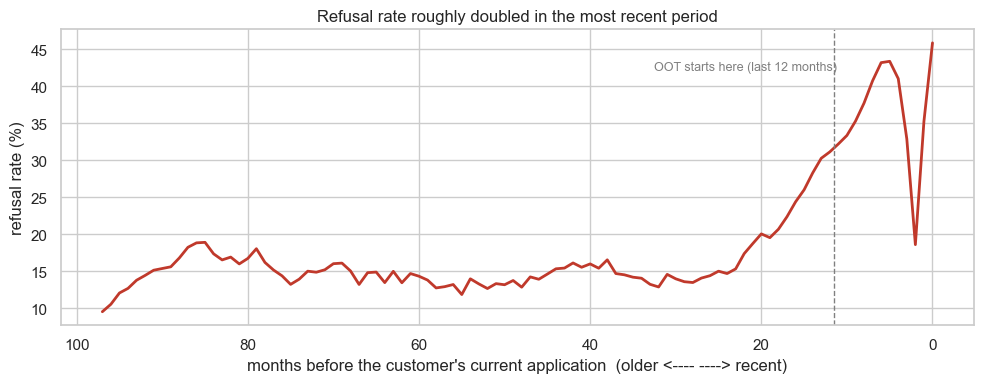

rows-weighted refusal rate, development window (>= 12 months ago): 17.35%
rows-weighted refusal rate, OOT window (< 12 months ago)        : 37.39%

last 12 months (most recent first):
 MONTHS_AGO     n  refusal_pct
          0 14897        45.83
          1 11929        35.24
          2  9973        18.61
          3 15837        32.86
          4 21372        41.00
          5 27122        43.34
          6 31786        43.16
          7 32938        40.71
          8 34266        37.70
          9 33820        35.26
         10 33324        33.34
         11 33700        32.19

saved: ../outputs/dashboard_time_trend.csv and ../outputs/eda_time_trend.png
Free RAM (GB): 1.5


In [3]:
# Cell C - refusal rate over time (ALL SPLITS: business fact for the dashboard, not a model feature)
# DAYS_DECISION is relative to each customer's own current application, so there are no calendar
# dates. We use "months before current application" as the timeline (0 = most recent month).
# Note: month 12 sits exactly on the OOT boundary, so it contains a few development rows too.
df["MONTHS_AGO"] = (-df["DAYS_DECISION"] // 30).astype("int16")

trend = (df.groupby(["MONTHS_AGO", "SPLIT"], observed=True)["REFUSED"]
           .agg(n="size", refusal_pct="mean")
           .reset_index())
trend["refusal_pct"] = (trend["refusal_pct"] * 100).round(2)
trend.to_csv(OUT + "dashboard_time_trend.csv", index=False)

overall = (df.groupby("MONTHS_AGO")["REFUSED"]
             .agg(n="size", refusal_pct="mean")
             .reset_index())
overall["refusal_pct"] = (overall["refusal_pct"] * 100).round(2)

dev = overall[overall["MONTHS_AGO"] >= 12]
oot = overall[overall["MONTHS_AGO"] < 12]
dev_rate = (dev["n"] * dev["refusal_pct"]).sum() / dev["n"].sum()
oot_rate = (oot["n"] * oot["refusal_pct"]).sum() / oot["n"].sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(overall["MONTHS_AGO"], overall["refusal_pct"], lw=2, color="#c0392b")
ax.axvline(11.5, color="grey", ls="--", lw=1)
ax.text(11.2, overall["refusal_pct"].max() * 0.92, "OOT starts here (last 12 months)",
        color="grey", fontsize=9, ha="right")
ax.invert_xaxis()
ax.set_xlabel("months before the customer's current application  (older <---- ----> recent)")
ax.set_ylabel("refusal rate (%)")
ax.set_title("Refusal rate roughly doubled in the most recent period")
fig.tight_layout()
fig.savefig(OUT + "eda_time_trend.png", dpi=120)
plt.show()

print("rows-weighted refusal rate, development window (>= 12 months ago): %.2f%%" % dev_rate)
print("rows-weighted refusal rate, OOT window (< 12 months ago)        : %.2f%%" % oot_rate)
print()
print("last 12 months (most recent first):")
print(overall.head(12)[["MONTHS_AGO", "n", "refusal_pct"]].to_string(index=False))
print()
print("saved:", OUT + "dashboard_time_trend.csv", "and", OUT + "eda_time_trend.png")
print("Free RAM (GB):", free_ram_gb())


In [4]:
# Cell D - drift check: development vs OOT (same population?)
# Column by column, so we never hold a second copy of the table.
feats = [c for c in df.columns if c not in APP_LEVEL]

rows = []
for c in feats:
    dev_col, oot_col = df.loc[tr_mask, c], df.loc[oot_mask, c]
    row = {"column": c,
           "miss%_dev": round(float(dev_col.isna().mean() * 100), 2),
           "miss%_oot": round(float(oot_col.isna().mean() * 100), 2)}
    row["miss_gap"] = round(row["miss%_oot"] - row["miss%_dev"], 2)
    if pd.api.types.is_numeric_dtype(dev_col.dtype):
        d, o = dev_col.dropna(), oot_col.dropna()
        sd = float(d.std())
        row["mean_dev"] = round(float(d.mean()), 3)
        row["mean_oot"] = round(float(o.mean()), 3)
        row["shift_in_sd"] = round(float((o.mean() - d.mean()) / sd), 3) if sd > 0 else np.nan
    rows.append(row)

drift = pd.DataFrame(rows)
drift.to_csv(OUT + "dashboard_drift.csv", index=False)

print("largest missingness gaps (OOT - dev), percentage points:")
print(drift.reindex(drift["miss_gap"].abs().sort_values(ascending=False).index)
          .head(10)[["column", "miss%_dev", "miss%_oot", "miss_gap"]].to_string(index=False))
print()
print("largest mean shifts, in units of development std dev:")
d2 = drift.dropna(subset=["shift_in_sd"])
print(d2.reindex(d2["shift_in_sd"].abs().sort_values(ascending=False).index)
      .head(10)[["column", "mean_dev", "mean_oot", "shift_in_sd"]].to_string(index=False))
print()
print("saved:", OUT + "dashboard_drift.csv")
print("Free RAM (GB):", free_ram_gb())


largest missingness gaps (OOT - dev), percentage points:
                 column  miss%_dev  miss%_oot  miss_gap
      CUST_EXT_SOURCE_2      15.51      12.78     -2.73
      CUST_FLAG_OWN_CAR      15.38      12.67     -2.71
CUST_NAME_CONTRACT_TYPE      15.38      12.67     -2.71
  CUST_AMT_INCOME_TOTAL      15.38      12.67     -2.71
      CUST_CNT_CHILDREN      15.38      12.67     -2.71
        CUST_AMT_CREDIT      15.38      12.67     -2.71
   CUST_FLAG_OWN_REALTY      15.38      12.67     -2.71
  CUST_FLAG_CONT_MOBILE      15.38      12.67     -2.71
 CUST_NAME_HOUSING_TYPE      15.38      12.67     -2.71
CUST_NAME_FAMILY_STATUS      15.38      12.67     -2.71

largest mean shifts, in units of development std dev:
                         column   mean_dev   mean_oot  shift_in_sd
                     MONTHS_AGO     42.124      6.761       -1.423
    CUST_DAYS_LAST_PHONE_CHANGE  -1157.457   -905.106        0.315
CUST_AMT_REQ_CREDIT_BUREAU_YEAR      2.607      3.053        0.212
    

CHANNEL_TYPE (train):
     feature                   category      n  refusal_rate
CHANNEL_TYPE           Regional / Local  59928         10.24
CHANNEL_TYPE                      Stone 125048         10.38
CHANNEL_TYPE               Country-wide 273018         13.59
CHANNEL_TYPE             Contact center  17672         20.99
CHANNEL_TYPE    Credit and cash offices 210870         25.45
CHANNEL_TYPE                 Car dealer    294         31.63
CHANNEL_TYPE            AP+ (Cash loan)  25249         34.30
CHANNEL_TYPE Channel of corporate sales   2388         47.36

NAME_CLIENT_TYPE (train):
         feature  category      n  refusal_rate
NAME_CLIENT_TYPE       New 187998          4.80
NAME_CLIENT_TYPE Refreshed  58529         11.16
NAME_CLIENT_TYPE  Repeater 467940         23.06


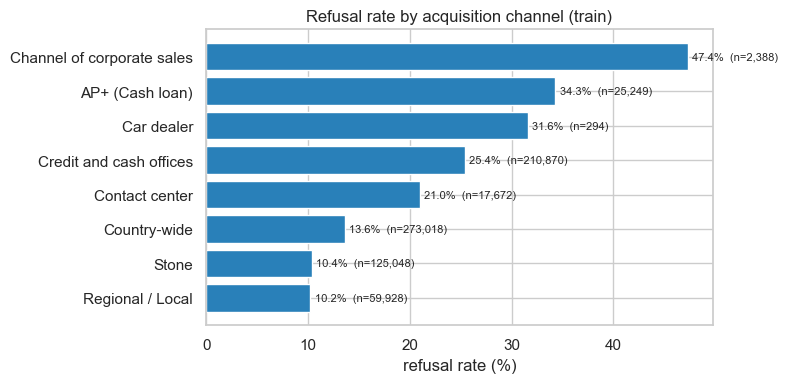


saved: ../outputs/dashboard_refusal_by_category.csv and ../outputs/eda_channel.png
Free RAM (GB): 3.07


In [5]:
# Cell E - application-level categories vs refusal (TRAIN only)
cat_feats = [
    "NAME_CONTRACT_TYPE", "NAME_CLIENT_TYPE", "NAME_PORTFOLIO", "NAME_PRODUCT_TYPE",
    "CHANNEL_TYPE", "NAME_YIELD_GROUP", "PRODUCT_COMBINATION", "NAME_GOODS_CATEGORY",
    "NAME_PAYMENT_TYPE", "NAME_CASH_LOAN_PURPOSE", "NAME_TYPE_SUITE", "NAME_SELLER_INDUSTRY",
    "WEEKDAY_APPR_PROCESS_START", "FLAG_LAST_APPL_PER_CONTRACT",
]

recs = []
for c in cat_feats:
    g = (df.loc[tr_mask, [c, "REFUSED"]].groupby(c, observed=True)["REFUSED"]
           .agg(n="size", refusal_rate="mean").reset_index())
    g = g.rename(columns={c: "category"})
    g["refusal_rate"] = (g["refusal_rate"] * 100).round(2)
    g["feature"] = c
    recs.append(g[["feature", "category", "n", "refusal_rate"]])

cat_long = pd.concat(recs, ignore_index=True)
cat_long.to_csv(OUT + "dashboard_refusal_by_category.csv", index=False)

top = cat_long[cat_long["feature"] == "CHANNEL_TYPE"].sort_values("refusal_rate")
print("CHANNEL_TYPE (train):")
print(top.to_string(index=False))
print()
print("NAME_CLIENT_TYPE (train):")
print(cat_long[cat_long["feature"] == "NAME_CLIENT_TYPE"].sort_values("refusal_rate").to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top["category"].astype(str), top["refusal_rate"], color="#2980b9")
ax.set_xlabel("refusal rate (%)")
ax.set_title("Refusal rate by acquisition channel (train)")
for i, (v, n) in enumerate(zip(top["refusal_rate"], top["n"])):
    ax.text(v + 0.4, i, f"{v:.1f}%  (n={n:,})", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(OUT + "eda_channel.png", dpi=120)
plt.show()

print()
print("saved:", OUT + "dashboard_refusal_by_category.csv", "and", OUT + "eda_channel.png")
print("Free RAM (GB):", free_ram_gb())


In [6]:
# Cell F - customer-profile categories vs refusal (TRAIN only)
cust_cat_feats = [
    "CUST_CODE_GENDER", "CUST_NAME_INCOME_TYPE", "CUST_NAME_EDUCATION_TYPE",
    "CUST_NAME_FAMILY_STATUS", "CUST_NAME_HOUSING_TYPE", "CUST_OCCUPATION_TYPE",
    "CUST_ORGANIZATION_TYPE", "CUST_FLAG_OWN_CAR", "CUST_FLAG_OWN_REALTY",
]

recs = []
for c in cust_cat_feats:
    g = (df.loc[tr_mask, [c, "REFUSED"]].groupby(c, observed=True)["REFUSED"]
           .agg(n="size", refusal_rate="mean").reset_index())
    g = g.rename(columns={c: "category"})
    g["refusal_rate"] = (g["refusal_rate"] * 100).round(2)
    g["feature"] = c
    recs.append(g[["feature", "category", "n", "refusal_rate"]])

cust_long = pd.concat(recs, ignore_index=True)
cust_long.to_csv(OUT + "dashboard_refusal_by_customer_category.csv", index=False)

print("education (train):")
print(cust_long[cust_long["feature"] == "CUST_NAME_EDUCATION_TYPE"].sort_values("refusal_rate").to_string(index=False))
print()
print("occupation, n >= 500 (train):")
occ = cust_long[(cust_long["feature"] == "CUST_OCCUPATION_TYPE") & (cust_long["n"] >= 500)]
print(occ.sort_values("refusal_rate").to_string(index=False))
print()
print("saved:", OUT + "dashboard_refusal_by_customer_category.csv")
print("Free RAM (GB):", free_ram_gb())


education (train):
                 feature                      category      n  refusal_rate
CUST_NAME_EDUCATION_TYPE               Lower secondary   7341         16.29
CUST_NAME_EDUCATION_TYPE Secondary / secondary special 444650         16.60
CUST_NAME_EDUCATION_TYPE               Academic degree    286         17.13
CUST_NAME_EDUCATION_TYPE              Higher education 133112         17.39
CUST_NAME_EDUCATION_TYPE             Incomplete higher  19219         19.05

occupation, n >= 500 (train):
             feature              category      n  refusal_rate
CUST_OCCUPATION_TYPE           Secretaries   2502         14.19
CUST_OCCUPATION_TYPE        Medicine staff  17297         15.55
CUST_OCCUPATION_TYPE High skill tech staff  21129         15.76
CUST_OCCUPATION_TYPE           Accountants  18517         16.03
CUST_OCCUPATION_TYPE              HR staff    948         16.24
CUST_OCCUPATION_TYPE Private service staff   4980         16.45
CUST_OCCUPATION_TYPE            Core staff  50

AMT_APPLICATION (deciles, train; Q1 = lowest):
        feature band_label   band_low   band_high     n  refusal_rate
AMT_APPLICATION         Q1     -0.001   21550.500 71481         22.24
AMT_APPLICATION         Q2  21550.500   35770.500 71435         10.07
AMT_APPLICATION         Q3  35770.500   49450.500 71478         12.43
AMT_APPLICATION         Q4  49450.500   68728.500 71396         11.44
AMT_APPLICATION         Q5  68728.500   90940.500 71445         12.20
AMT_APPLICATION         Q6  90940.500  125669.700 71445         12.63
AMT_APPLICATION         Q7 125669.700  167400.000 71454         17.15
AMT_APPLICATION         Q8 167400.000  238418.191 71439         22.79
AMT_APPLICATION         Q9 238418.191  450000.000 74366         22.52
AMT_APPLICATION        Q10 450000.000 5850000.000 68528         29.60

CUST_AMT_INCOME_TOTAL (deciles, train; Q1 = lowest):
              feature band_label   band_low  band_high     n  refusal_rate
CUST_AMT_INCOME_TOTAL         Q1  25649.999    90000.0

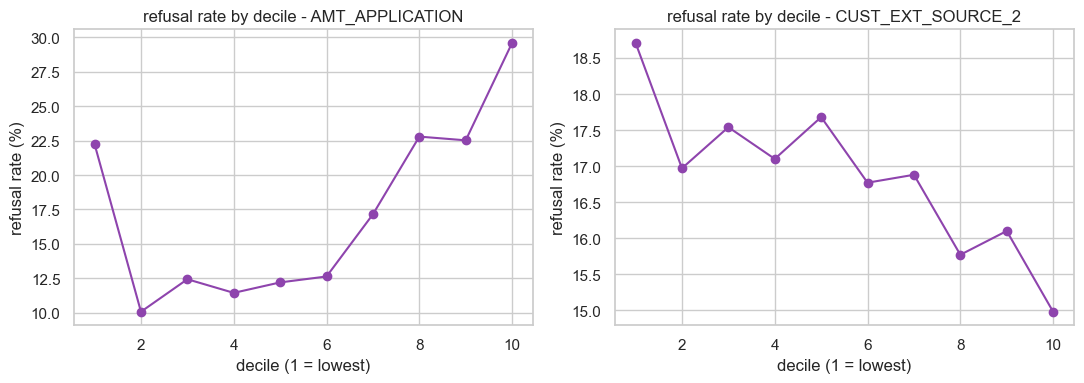

saved: ../outputs/dashboard_refusal_by_band.csv and ../outputs/eda_amount_bands.png
Free RAM (GB): 2.99


In [7]:
# Cell G - numeric bands vs refusal (TRAIN only)
num_feats = [
    "AMT_APPLICATION", "AMT_GOODS_PRICE", "AMT_DOWN_PAYMENT",
    "CUST_AMT_INCOME_TOTAL", "CUST_AMT_CREDIT", "CUST_AMT_ANNUITY",
    "AGE_YEARS", "CUST_EXT_SOURCE_2", "CUST_EXT_SOURCE_3",
]

recs = []
for c in num_feats:
    tmp = df.loc[tr_mask, [c, "REFUSED"]].dropna(subset=[c])
    if len(tmp) == 0:
        continue
    bands = pd.qcut(tmp[c], q=10, duplicates="drop")
    g = (tmp.groupby(bands, observed=True)["REFUSED"]
           .agg(n="size", refusal_rate="mean").reset_index())
    g = g.rename(columns={g.columns[0]: "band"})
    g["refusal_rate"] = (g["refusal_rate"] * 100).round(2)
    g["feature"] = c
    g["band_low"] = g["band"].apply(lambda iv: round(float(iv.left), 3))
    g["band_high"] = g["band"].apply(lambda iv: round(float(iv.right), 3))
    g["band_label"] = ["Q%d" % (i + 1) for i in range(len(g))]
    recs.append(g[["feature", "band_label", "band_low", "band_high", "n", "refusal_rate"]])

num_long = pd.concat(recs, ignore_index=True)
num_long.to_csv(OUT + "dashboard_refusal_by_band.csv", index=False)

for c in ["AMT_APPLICATION", "CUST_AMT_INCOME_TOTAL", "CUST_EXT_SOURCE_2"]:
    print(c, "(deciles, train; Q1 = lowest):")
    print(num_long[num_long["feature"] == c].to_string(index=False))
    print()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, ["AMT_APPLICATION", "CUST_EXT_SOURCE_2"]):
    part = num_long[num_long["feature"] == c]
    ax.plot(range(1, len(part) + 1), part["refusal_rate"], marker="o", color="#8e44ad")
    ax.set_title("refusal rate by decile - " + c)
    ax.set_xlabel("decile (1 = lowest)")
    ax.set_ylabel("refusal rate (%)")
fig.tight_layout()
fig.savefig(OUT + "eda_amount_bands.png", dpi=120)
plt.show()

print("saved:", OUT + "dashboard_refusal_by_band.csv", "and", OUT + "eda_amount_bands.png")
print("Free RAM (GB):", free_ram_gb())


Free RAM after releasing the big table (GB): 2.99



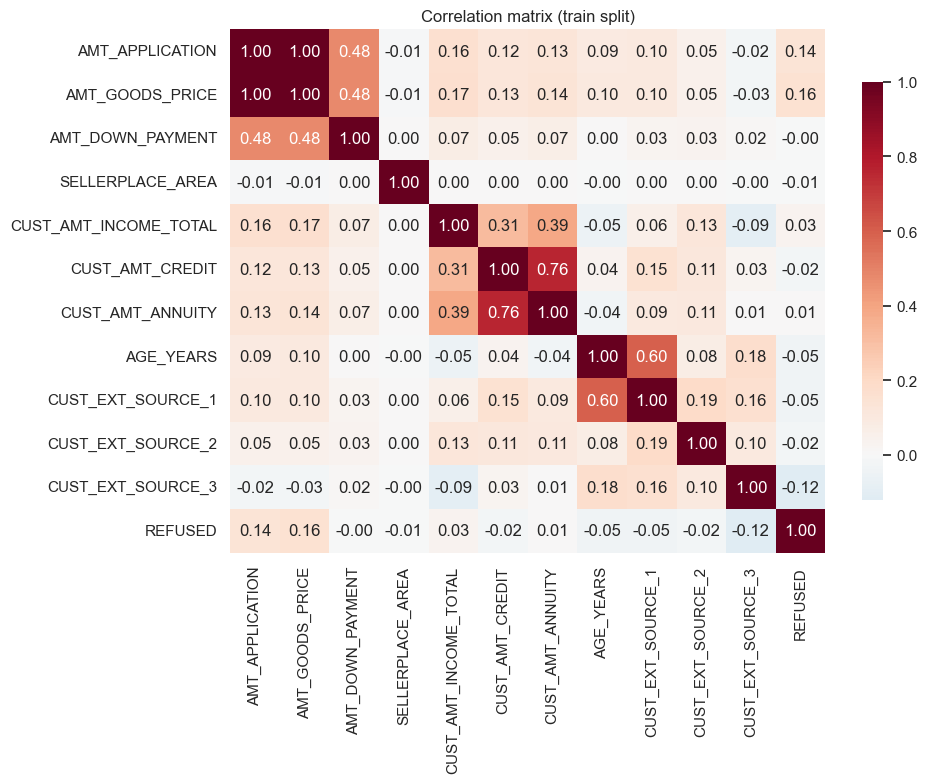

absolute correlation with REFUSED, highest first (train):
AMT_GOODS_PRICE          0.157
AMT_APPLICATION          0.140
CUST_EXT_SOURCE_3        0.122
CUST_EXT_SOURCE_1        0.047
AGE_YEARS                0.045
CUST_AMT_INCOME_TOTAL    0.033
CUST_AMT_CREDIT          0.024
CUST_EXT_SOURCE_2        0.023
CUST_AMT_ANNUITY         0.008
SELLERPLACE_AREA         0.006
AMT_DOWN_PAYMENT         0.003

saved: ../outputs/eda_corr.png
Free RAM (GB): 2.94


In [8]:
# Cell H - correlation of the main numeric features (TRAIN only), then free the big table
heat_cols = [
    "AMT_APPLICATION", "AMT_GOODS_PRICE", "AMT_DOWN_PAYMENT", "SELLERPLACE_AREA",
    "CUST_AMT_INCOME_TOTAL", "CUST_AMT_CREDIT", "CUST_AMT_ANNUITY",
    "AGE_YEARS", "CUST_EXT_SOURCE_1", "CUST_EXT_SOURCE_2", "CUST_EXT_SOURCE_3",
    "REFUSED",
]
corr = df.loc[tr_mask, heat_cols].corr(numeric_only=True)
del df
gc.collect()
print("Free RAM after releasing the big table (GB):", free_ram_gb())
print()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation matrix (train split)")
fig.tight_layout()
fig.savefig(OUT + "eda_corr.png", dpi=120)
plt.show()

print("absolute correlation with REFUSED, highest first (train):")
print(corr["REFUSED"].drop("REFUSED").abs().sort_values(ascending=False).round(3).to_string())
print()
print("saved:", OUT + "eda_corr.png")
print("Free RAM (GB):", free_ram_gb())


In [9]:
# Cell I - list everything EDA produced
wanted = [
    "dashboard_time_trend.csv", "dashboard_drift.csv",
    "dashboard_refusal_by_category.csv", "dashboard_refusal_by_customer_category.csv",
    "dashboard_refusal_by_band.csv",
    "eda_time_trend.png", "eda_channel.png", "eda_amount_bands.png", "eda_corr.png",
]
print("files in outputs/:")
for f in wanted:
    p = OUT + f
    if os.path.exists(p):
        print("  OK  %-48s %8.2f MB" % (f, os.path.getsize(p) / 1e6))
    else:
        print("  MISSING", f)
print()
print("Free RAM (GB):", free_ram_gb())
print("Next: notebooks/03_modelling_validation.ipynb")


files in outputs/:
  OK  dashboard_time_trend.csv                             0.01 MB
  OK  dashboard_drift.csv                                  0.01 MB
  OK  dashboard_refusal_by_category.csv                    0.01 MB
  OK  dashboard_refusal_by_customer_category.csv           0.01 MB
  OK  dashboard_refusal_by_band.csv                        0.00 MB
  OK  eda_time_trend.png                                   0.06 MB
  OK  eda_channel.png                                      0.04 MB
  OK  eda_amount_bands.png                                 0.06 MB
  OK  eda_corr.png                                         0.19 MB

Free RAM (GB): 2.94
Next: notebooks/03_modelling_validation.ipynb


## Business insights

Every number below comes from the tables printed in this notebook (refusal rates on the **train split**,
so nothing here has seen validation, test or OOT data). "x" = ratio against the comparison group.

1. **Corporate-channel applications are refused 4.6x more often than regional ones.**
   Channel of corporate sales: **47.36%** refused (n=2,388) vs Regional / Local: **10.24%** (n=59,928).
   *So what:* corporate sales routes generate almost every second refusal - the lender should renegotiate
   terms or pre-screen with this channel before underwriting spends time on the file.

2. **Repeaters are refused 4.8x more often than new customers.**
   Repeater: **23.06%** (n=467,940) vs New: **4.80%** (n=187,998); Refreshed sits in between at **11.16%**.
   *So what:* repeat application is itself a risk signal - a customer returning often means an earlier
   refusal was not resolved. Pre-screening repeaters would cut a large share of wasted reviews.

3. **Walk-in products are refused 3.0x more than cross-sold ones.**
   NAME_PRODUCT_TYPE walk-in: **49.20%** (n=73,581) vs x-sell: **16.48%** (n=221,775). By portfolio:
   Cards **31.38%** vs POS **9.42%** (3.3x). *So what:* how the product is sold matters as much as
   what is sold - cross-sold applications arrive better prepared.

4. **Requested amount shows a U-shape: both extremes are ~2-3x the middle.**
   Smallest decile Q1: **22.24%**, largest Q10: **29.60%**, vs the middle Q2: **10.07%**.
   *So what:* very small requests look like distress borrowing, very large ones exceed capacity;
   guiding customers to a mid-range amount would lift approval rates.

5. **Younger applicants are refused 1.5x more often than the oldest.**
   Youngest age decile: **20.71%** vs oldest: **13.54%**; the decline is steady across deciles.
   *So what:* thin files (young, short employment) drive refusals - the lender could steer this group
   to smaller first loans to build history.

6. **The external credit score is the cleanest monotonic driver: 2.4x between bottom and top decile.**
   CUST_EXT_SOURCE_3 bottom decile: **25.90%** vs top: **10.96%**, falling steadily every decile.
   *So what:* bureau scores already separate risk well - they should anchor any policy rules.

7. **Refusal rate nearly quintupled over the observed period: 9.48% (97 months ago) -> 45.83% (latest month).**
   *So what:* this is a policy change, not a population change - the drift table in this notebook shows
   feature means moved at most 0.32 standard deviations. The most recent year (used as the OOT test) is
   a genuinely harder exam, which is exactly why we kept it separate.

**Limitation - loan purpose:** after XNA/XAP cleaning only ~5% of applications state a purpose, so
per-category rates rest on small samples (e.g. "Payments on other loans" 76.07% but n=794). We do not
draw a business conclusion from this dimension; the missingness itself is captured by PURPOSE_STATED.